# 横磁場イジングモデル：Jordan-Wigner変換

横磁場イジングモデルの基底エネルギー$E_0$と横磁化$m_x(t)$を、Jordan-Wigner変換で求める。変換の定義・一般的な規則・BdG形式は [methods/02_jordan_wigner.ipynb](../../methods/02_jordan_wigner.ipynb)、模型の定義は [00_model.ipynb](00_model.ipynb) を参照。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 厳密対角化（src/qmb/operators.py, ed.py）と TFIM の定義（src/qmb/models.py）
from qmb.operators import plus_state
from qmb.ed import ground_state, time_evolve_expectation
from qmb.models import tfim_hamiltonian as hamiltonian, magnetization_x

# Jordan-Wigner変換の一般的な関数（src/qmb/free_fermion.py）
from qmb.free_fermion import bdg_matrix, quasiparticle_energies, ground_energy

# TFIM の自由フェルミオン表示（src/qmb/models.py）
#   tfim_free_fermion : 行列 A, B と定数項
#   mx_jw             : |+...+> からのクエンチ後の m_x(t)
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: tfim_hamiltonian??）
from qmb.models import tfim_free_fermion, tfim_mx_quench_ff as mx_jw

## 1. どの軸を粒子数にとるか

横磁場イジングモデル$H = -J\sum_j Z_jZ_{j+1} - h\sum_j X_j$では、**$X$の固有状態**を空/占有にとる。

- $\ket{+}$ : フェルミオンがいない（$n_j=0$）
- $\ket{-}$ : フェルミオンがいる（$n_j=1$）

[methods/02_jordan_wigner.ipynb](../../methods/02_jordan_wigner.ipynb)の一般論は$Z$を粒子数の軸にして書いたので、そこで$Z\to X$、$X\to Z$と名前を入れ替えれば（$Y\to -Y$）そのまま使える。ひもは$\prod_{k<j}X_k$になり

\begin{equation}
X_j = 1 - 2c_j^\dagger c_j,\quad Z_j = \left(\prod_{k<j} X_k\right)(c_j + c_j^\dagger)
\end{equation}

となる。

$Z$の固有状態を使うと、横磁場の項$X_j$に長いひもが残って2次形式にならない（一般論の2節の表）。単独で現れる$X_j$を粒子数にとり、ペアで現れる$Z_jZ_{j+1}$をひもが打ち消し合う側にすることで、両方の項が2次形式になる。この選び方の副産物として、初期状態$\ket{+\cdots+}$が**フェルミオンの真空**$\ket{0}$になる。

## 2. ハミルトニアンをフェルミオンで書く

それぞれ代入する。

- **横磁場の項**

  そのまま代入して

  \begin{equation}
  -h\sum_j X_j = -h\sum_j\left(1 - 2c_j^\dagger c_j\right)
  \end{equation}

- **イジング相互作用の項**

  $X_k^2 = 1$なので、隣り合うサイトではひもがほぼ打ち消し合い、$X_j$が1個だけ残る。

  \begin{equation}
  Z_j Z_{j+1} = (c_j + c_j^\dagger)\,X_j\,(c_{j+1} + c_{j+1}^\dagger)
  \end{equation}

  ここで$c_j c_j^\dagger c_j = c_j,\ c_j^\dagger c_j^\dagger c_j = 0$を使うと

  \begin{equation}
  (c_j + c_j^\dagger)X_j = (c_j + c_j^\dagger)(1 - 2c_j^\dagger c_j) = c_j^\dagger - c_j
  \end{equation}

  なので

  \begin{equation}
  \begin{aligned}
  Z_j Z_{j+1}
  &= (c_j^\dagger - c_j)(c_{j+1} + c_{j+1}^\dagger) \\
  &= c_j^\dagger c_{j+1} + c_{j+1}^\dagger c_j + c_j^\dagger c_{j+1}^\dagger + c_{j+1} c_j
  \end{aligned}
  \end{equation}

以上より、開放境界条件のハミルトニアンは

\begin{equation}
H = -J\sum_{j=1}^{n-1}\left(c_j^\dagger c_{j+1} + c_{j+1}^\dagger c_j + c_j^\dagger c_{j+1}^\dagger + c_{j+1} c_j\right) - h\sum_{j=1}^{n}\left(1 - 2c_j^\dagger c_j\right)
\end{equation}

となる。第1項の前半は隣のサイトへの**ホッピング**、後半は**ペアの生成・消滅**を表す。フェルミオンの数は保存しないが、ペアでしか増減しないので偶奇（パリティ）は保存する。

重要なのは、$H$が**フェルミオン演算子の2次形式**になっていることである。2次形式は相互作用のない自由粒子と同じで、$n$個の1粒子モードに分解して厳密に解ける。

> **周期境界条件の場合**
>
> 境界の項$Z_n Z_1$では左右のひもが打ち消し合わず、全パリティ$P = \prod_k X_k$が残る。そのためパリティごとにフェルミオンの境界条件が（反）周期的に変わる。基底状態は$P=+1$（反周期）の側にあり、波数$k = \pm\frac{\pi}{n}, \pm\frac{3\pi}{n}, \cdots$についてフーリエ変換すると
>
> \begin{equation}
> \varepsilon_k = 2\sqrt{J^2 + h^2 - 2Jh\cos k},\quad E_0 = -\frac{1}{2}\sum_k \varepsilon_k
> \end{equation}
>
> となる。$k\to 0$で$\varepsilon_k\to 2|J-h|$なので、$h=J$でギャップが閉じる（量子相転移）。以下では開放境界条件で計算する。

## 3. 行列$A, B$と基底エネルギー$E_0$

2節の結果を一般論の2次形式$H = \sum c^\dagger A c + \frac12(c^\dagger B c^\dagger + \mathrm{h.c.}) + \mathrm{const}$と見比べる。$-J c_j^\dagger c_{j+1}^\dagger = \frac12\left(-Jc_j^\dagger c_{j+1}^\dagger + Jc_{j+1}^\dagger c_j^\dagger\right)$に注意すると

\begin{equation}
A_{jj} = 2h,\quad A_{j,j+1} = A_{j+1,j} = -J,\quad B_{j,j+1} = -J,\quad B_{j+1,j} = +J,\quad \mathrm{const} = -hn
\end{equation}

で、それ以外の成分は0である。定数項は$\frac{1}{2}\mathrm{tr}A + \mathrm{const} = hn - hn = 0$と打ち消し合うので、一般論の結果から

\begin{equation}
E_0 = -\frac{1}{2}\sum_{k=1}^{n}\varepsilon_k
\end{equation}

となる（$\varepsilon_k$は$H_{\mathrm{BdG}} = \begin{pmatrix} A & B \\ -B & -A\end{pmatrix}$の正の固有値）。

## 4. 横磁化$m_x(t)$

$X_j = 1 - 2c_j^\dagger c_j$より

\begin{equation}
M_x = \frac{1}{n}\sum_{j=1}^{n} X_j = 1 - \frac{2}{n}\sum_{j=1}^{n} c_j^\dagger c_j
\end{equation}

なので、各サイトの粒子数の時間発展がわかればよい。初期状態$\ket{+\cdots+}$はフェルミオンの真空なので、一般論の4節の真空からの式がそのまま使えて

\begin{equation}
m_x(t) = 1 - \frac{2}{n}\sum_{j,k}\left|\left(U_{12}(t)\right)_{jk}\right|^2,\quad U(t) = e^{-iH_{\mathrm{BdG}}t}
\end{equation}

である。$t=0$では$U_{12}=0$なので$m_x(0)=1$となる。真空からペアが生まれるほど横磁化が減る。

## 5. $n=2$の手計算

$n=2$（開放境界）の場合を手で計算し、[01_exact_diag.ipynb](01_exact_diag.ipynb)の結果と比べる。

- **基底エネルギー$E_0$**

  3節の定義より

  $$
  A = \begin{pmatrix} 2h & -J \\ -J & 2h \end{pmatrix},\quad
  B = \begin{pmatrix} 0 & -J \\ J & 0 \end{pmatrix}
  $$

  $H_{\mathrm{BdG}}$の固有値を求めるのに次の工夫を使う。$Q = \frac{1}{\sqrt{2}}\begin{pmatrix} I & I \\ I & -I\end{pmatrix}$で基底を変えると

  $$
  QH_{\mathrm{BdG}}Q = \begin{pmatrix} 0 & A-B \\ A+B & 0 \end{pmatrix}
  \Rightarrow
  (QH_{\mathrm{BdG}}Q)^2 = \begin{pmatrix} (A-B)(A+B) & 0 \\ 0 & (A+B)(A-B) \end{pmatrix}
  $$

  なので、$\varepsilon_k^2$は$(A-B)(A+B)$の固有値である。実際に計算すると

  $$
  (A-B)(A+B)
  = \begin{pmatrix} 2h & 0 \\ -2J & 2h \end{pmatrix}\begin{pmatrix} 2h & -2J \\ 0 & 2h \end{pmatrix}
  = \begin{pmatrix} 4h^2 & -4hJ \\ -4hJ & 4J^2+4h^2 \end{pmatrix}
  $$

  トレースが$4J^2+8h^2$、行列式が$16h^4$なので、固有値は

  $$
  \lambda = 2J^2 + 4h^2 \pm 2J\sqrt{J^2+4h^2} = \left(\sqrt{J^2+4h^2} \pm J\right)^2
  $$

  よって1粒子エネルギーは

  $$
  \varepsilon_\pm = \sqrt{J^2+4h^2} \pm J
  $$

  であり、基底エネルギーは

  $$
  E_0 = -\frac{1}{2}(\varepsilon_+ + \varepsilon_-) = -\sqrt{J^2+4h^2}
  $$

  となり、厳密対角化の手計算の結果と一致する。さらに励起状態も

  $$
  E_0 + \varepsilon_- = -J,\quad E_0 + \varepsilon_+ = J,\quad E_0 + \varepsilon_+ + \varepsilon_- = \sqrt{J^2+4h^2}
  $$

  となり、厳密対角化で求めた4つの固有値がすべて再現される。$2^2=4$個の多体の固有値が、たった2個の1粒子エネルギー$\varepsilon_\pm$の組み合わせで表されていることがわかる。

- **横磁化$m_x(t)$**

  $J=1, h=0.5$では$\varepsilon_\pm = \sqrt{2}\pm1$である。$m_x(t)$は4節の式で数値的に計算し、厳密対角化の手計算の結果$\cos^2(\sqrt{2}t)$と比較する。

## 6. コードで確かめる

3節・4節の式を、一般的な関数（`qmb.free_fermion`）とTFIMの行列$A, B$（`qmb.models.tfim_free_fermion`）で計算し、$n=2$の手計算と比較する。

A =
 [[ 1. -1.]
 [-1.  1.]]
B =
 [[ 0. -1.]
 [ 1.  0.]]
1粒子エネルギー ε = [0.41421356 2.41421356]  (手計算: √2-1 = 0.414214, √2+1 = 2.414214)
基底エネルギー E0 (JW)        = -1.414214
基底エネルギー E0 (厳密対角化) = -1.414214


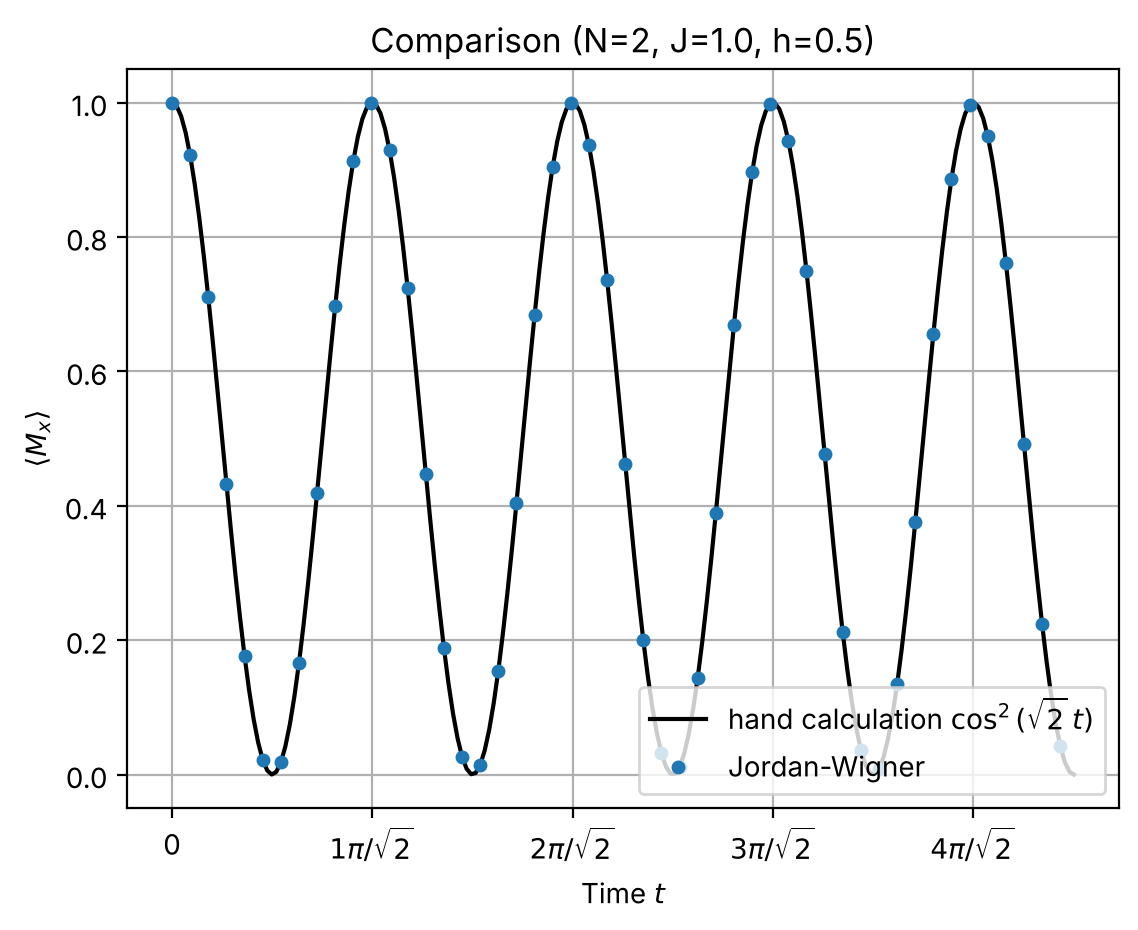

In [2]:
# 例: N=2, J=1, h=0.5
N = 2
J = 1.0
h = 0.5

A, B, const = tfim_free_fermion(N, J, h)   # 3節の行列 A, B と定数項 -hn
print("A =\n", A)
print("B =\n", B)

eps = quasiparticle_energies(bdg_matrix(A, B))
E0_jw = ground_energy(A, B, const)
print(f"1粒子エネルギー ε = {eps}  (手計算: √2-1 = {np.sqrt(2)-1:.6f}, √2+1 = {np.sqrt(2)+1:.6f})")
print(f"基底エネルギー E0 (JW)        = {E0_jw:.6f}")
print(f"基底エネルギー E0 (厳密対角化) = {ground_state(hamiltonian(N, J, h))[0]:.6f}")

ts = np.linspace(0, 10, 200)
mx = mx_jw(N, J, h, ts)

T = np.pi / np.sqrt(2)   # 周期
plt.plot(ts, np.cos(np.sqrt(2) * ts)**2, "k-", label=r"hand calculation $\cos^2(\sqrt{2}\,t)$")
plt.plot(ts[::4], mx[::4], "o", ms=4, label="Jordan-Wigner")
plt.xticks([k * T for k in range(5)], ["0"] + [rf"${k}\pi/\sqrt{{2}}$" for k in range(1, 5)])
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Comparison (N={N}, J={J}, h={h})")
plt.legend(loc="lower right")
plt.grid()
plt.show()

$n=2$では手計算と一致した。$n$を大きくしたときの厳密対角化との比較や、厳密対角化では扱えない大きな$n$の計算は、[11_ground_state.ipynb](11_ground_state.ipynb)と[12_quench_dynamics.ipynb](12_quench_dynamics.ipynb)で行う。

なお、横磁場イジングモデルがこのように解けるのは、$H$がフェルミオンの2次形式になるという**この模型特有の性質**による。縦磁場$\sum_j Z_j$を加えると、$Z_j$単独の項に長いひもが残って2次形式でなくなり、この方法は使えない。

---
**前へ**: [01 厳密対角化](01_exact_diag.ipynb)　｜　**次へ**: [03 Trotter分解](03_trotter.ipynb)